In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Part 1. Data Selection

The trading date that was selected was March 3rd with an expiration date of March 7th, as it has at least three calendar days remaining until expiration.

We then used Python to examine the stock price, time to expiration, interest rates, and available exercise prices. We also plotted the observed call options price against exercise prices, and then removed any unreliable observations, such as those with a lower ask than bid, for example.

Trading Date: 2025-03-03
Expiration Date: 2025-03-07
Calendar Days to Expiration: 4
Stock Price: $43.795
Interest Rate: 0.046861 (4.686%)
Dividend Yield: 0.019023 (1.902%)
Time to Expiration: 0.014116 years
Available Exercise Prices: [25.0, 29.0, 30.0, 31.0, 32.0, 33.0, 34.0, 35.0, 35.5, 36.0, 36.5, 37.0, 37.5, 38.0, 38.5, 39.0, 39.5, 40.0, 40.5, 41.0, 41.5, 42.0, 42.5, 43.0, 43.5, 44.0, 44.5, 45.0, 45.5, 46.0, 46.5, 47.0, 47.5, 48.0, 48.5, 49.0, 49.5, 50.0, 51.0, 52.0, 53.0, 55.0]

Total call options: 42
Retained observations: 21
Excluded observations: 21

Retained options:
 okey_xx  bidPrc  askPrc  mid_price  spread  relative_spread  openInterest
    25.0   18.60   18.95     18.775    0.35         0.018642             5
    29.0   14.65   14.95     14.800    0.30         0.020270             2
    34.0    9.65    9.95      9.800    0.30         0.030612             1
    35.0    8.65    8.90      8.775    0.25         0.028490            12
    35.5    8.20    8.45      8.325    0.25

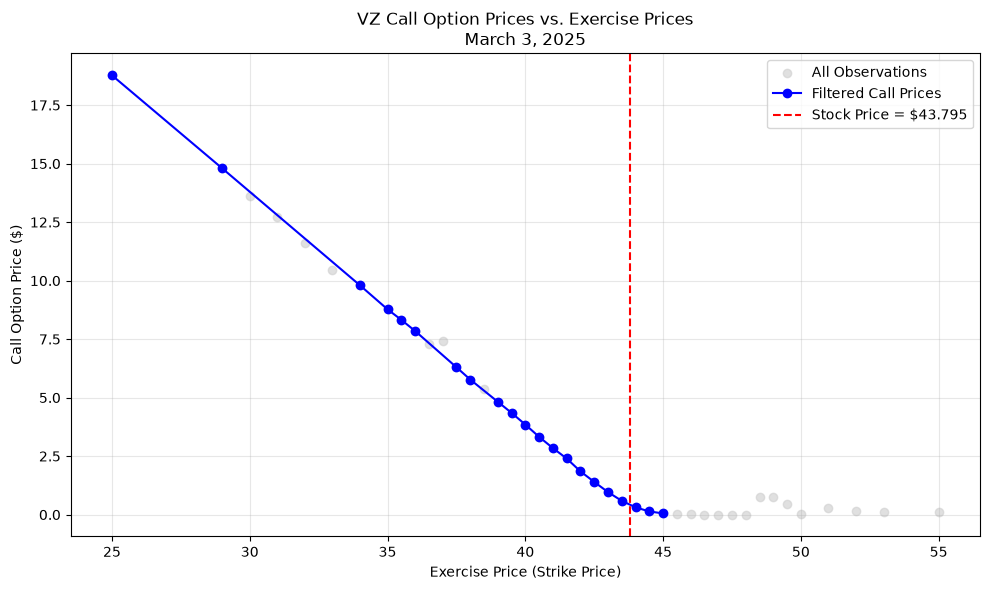

In [2]:
# 1. Load the dataset
df = pd.read_csv("VZ.csv")

df["tradingDate"] = pd.to_datetime(df["tradingDate"])
df["okey_date"] = pd.to_datetime(df["okey_date"])

# 2. Select trading date, expiration, and call options
trading_date = pd.Timestamp("2025-03-03")
expiration_date = pd.Timestamp("2025-03-07")

calls = df[
    (df["tradingDate"] == trading_date) &
    (df["okey_date"] == expiration_date) &
    (df["okey_cp"] == "Call")
].copy()

if calls.empty:
    raise ValueError("No matching call options found.")

# 3. Identify key variables
stock_price = calls["uClose"].iloc[0]
interest_rate = calls["rate"].iloc[0]
dividend_yield = calls["sdiv"].iloc[0]
time_to_expiration = calls["years"].iloc[0]
calendar_days = (expiration_date - trading_date).days
strikes = sorted(calls["okey_xx"].unique())

assert calendar_days >= 3

print("Trading Date:", trading_date.date())
print("Expiration Date:", expiration_date.date())
print("Calendar Days to Expiration:", calendar_days)
print(f"Stock Price: ${stock_price:.3f}")
print(f"Interest Rate: {interest_rate:.6f} ({interest_rate:.3%})")
print(f"Dividend Yield: {dividend_yield:.6f} ({dividend_yield:.3%})")
print(f"Time to Expiration: {time_to_expiration:.6f} years")
print("Available Exercise Prices:", [float(x) for x in strikes])

# 4. Calculate mid-prices and bid-ask spreads
calls["mid_price"] = (
    calls["bidPrc"] + calls["askPrc"]
) / 2

calls["spread"] = calls["askPrc"] - calls["bidPrc"]

calls["relative_spread"] = np.where(
    calls["mid_price"] > 0,
    calls["spread"] / calls["mid_price"],
    np.inf
)

# 5. Filter unreliable observations
# Require:
# - Positive bid
# - Ask >= bid
# - Absolute spread <= $0.50
# - Relative spread <= 25%
# - Positive open interest

valid = (
    (calls["bidPrc"] > 0) &
    (calls["askPrc"] >= calls["bidPrc"]) &
    (calls["spread"] <= 0.50) &
    (calls["relative_spread"] <= 0.25) &
    (calls["openInterest"] > 0)
)

clean_calls = calls[valid].copy()
excluded_calls = calls[~valid].copy()

clean_calls = clean_calls.sort_values("okey_xx")

# 6. Print results
print("\nTotal call options:", len(calls))
print("Retained observations:", len(clean_calls))
print("Excluded observations:", len(excluded_calls))

print("\nRetained options:")
print(clean_calls[
    ["okey_xx", "bidPrc", "askPrc",
     "mid_price", "spread", "relative_spread",
     "openInterest"]
].to_string(index=False))

print("\nExcluded options:")
print(excluded_calls[
    ["okey_xx", "bidPrc", "askPrc",
     "spread", "relative_spread", "openInterest"]
].to_string(index=False))

# 7. Plot observed call prices against strike prices
plt.figure(figsize=(10, 6))

plt.scatter(
    calls["okey_xx"],
    calls["mid_price"],
    color="lightgray",
    label="All Observations",
    alpha=0.7
)

plt.plot(
    clean_calls["okey_xx"],
    clean_calls["mid_price"],
    "o-",
    color="blue",
    label="Filtered Call Prices"
)

plt.axvline(
    stock_price,
    color="red",
    linestyle="--",
    label=f"Stock Price = ${stock_price:.3f}"
)

plt.xlabel("Exercise Price (Strike Price)")
plt.ylabel("Call Option Price ($)")
plt.title("VZ Call Option Prices vs. Exercise Prices\nMarch 3, 2025")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Part 2. Estimating the Lognormal Distribution


In [3]:
from scipy.optimize import minimize_scalar
from scipy.stats import norm, lognorm

# Use the cleaned observations from Part 1
S0 = float(clean_calls["uClose"].iloc[0])
r = float(clean_calls["rate"].iloc[0])
q = float(clean_calls["sdiv"].iloc[0])
T = float(clean_calls["years"].iloc[0])

K = clean_calls["okey_xx"].to_numpy()
observed = clean_calls["mid_price"].to_numpy()

# Risk-neutral expected terminal stock price
expected_ST = S0 * np.exp((r - q) * T)

# Theoretical European call price
def call_price(K, mu, sigma):
    d1 = (mu + sigma**2 - np.log(K)) / sigma
    d2 = (mu - np.log(K)) / sigma

    return np.exp(-r * T) * (
        np.exp(mu + sigma**2 / 2) * norm.cdf(d1)
        - K * norm.cdf(d2)
    )

# Estimate sigma while imposing the forward-price condition
def objective(sigma):
    mu = np.log(expected_ST) - sigma**2 / 2
    theoretical = call_price(K, mu, sigma)
    return np.sum((theoretical - observed)**2)

result = minimize_scalar(
    objective,
    bounds=(0.000001, 0.30),
    method="bounded"
)

sigma_hat = float(result.x)
mu_hat = float(np.log(expected_ST) - sigma_hat**2 / 2)

print(f"Estimated Mu: {mu_hat:.6f}")
print(f"Estimated Sigma: {sigma_hat:.6f}")

Estimated Mu: 3.779627
Estimated Sigma: 0.023891


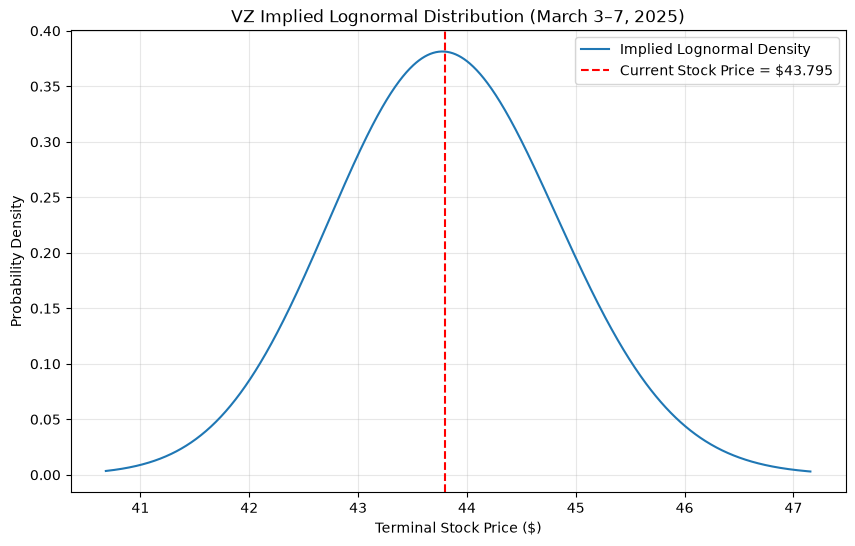

In [4]:
# Construct the fitted lognormal distribution
distribution = lognorm(s=sigma_hat, scale=np.exp(mu_hat))

prices = np.linspace(
    distribution.ppf(0.001),
    distribution.ppf(0.999),
    1000
)

density = distribution.pdf(prices)

plt.figure(figsize=(10, 6))

plt.plot(prices, density, label="Implied Lognormal Density")

plt.axvline(
    S0,
    color="red",
    linestyle="--",
    label=f"Current Stock Price = ${S0:.3f}"
)

plt.xlabel("Terminal Stock Price ($)")
plt.ylabel("Probability Density")
plt.title("VZ Implied Lognormal Distribution (March 3–7, 2025)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [5]:
# Mean of the terminal stock price
mean_ST = np.exp(mu_hat + sigma_hat**2 / 2)

# Standard deviation of the terminal stock price
std_ST = np.sqrt(
    (np.exp(sigma_hat**2) - 1)
    * np.exp(2 * mu_hat + sigma_hat**2)
)

# Probability of finishing below the current stock price
prob_below = norm.cdf(
    (np.log(S0) - mu_hat) / sigma_hat
)

print(f"Mean: ${mean_ST:.4f}")
print(f"Standard Deviation: ${std_ST:.4f}")
print(f"P(S_T < S0): {prob_below:.2%}")

Mean: $43.8122
Standard Deviation: $1.0469
P(S_T < S0): 49.82%


Part 3. Estimating a Mixture of Normals

In [6]:
from scipy.optimize import least_squares
from scipy.stats import norm, lognorm

# Same market inputs and cleaned options as Part 2
F = S0 * np.exp((r - q) * T)
discount = np.exp(-r * T)

# Expected payoff when terminal price is normal
def normal_payoff(K, mean, sd):
    d = (mean - K) / sd
    return (mean - K) * norm.cdf(d) + sd * norm.pdf(d)

# Parameterize the mixture so its mean equals F
def mixture_params(p):
    w, delta, sd1, sd2 = p
    mean1 = F - (1 - w) * delta
    mean2 = F + w * delta
    return w, mean1, sd1, mean2, sd2

# Theoretical mixture call prices
def mixture_call_price(K, p):
    w, m1, s1, m2, s2 = mixture_params(p)

    return discount * (
        w * normal_payoff(K, m1, s1)
        + (1 - w) * normal_payoff(K, m2, s2)
    )

# Minimize theoretical minus observed call prices
def residuals(p):
    return mixture_call_price(K, p) - observed

# Try multiple starting points
starts = [
    [0.10, 6.0, 0.20, 1.00],
    [0.25, 1.5, 1.00, 1.10],
    [0.50, 1.5, 1.00, 1.20],
    [0.70, 2.0, 1.50, 0.80],
    [0.30, 3.0, 1.00, 1.00]
]

fits = [
    least_squares(
        residuals,
        x0=start,
        bounds=(
            [0.005, 0, 0.1, 0.1],
            [0.995, 15, 10, 10]
        ),
        max_nfev=1200
    )
    for start in starts
]

result = min(fits, key=lambda x: np.sum(x.fun**2))

w, mu1, sd1, mu2, sd2 = mixture_params(result.x)
mixture_prices = mixture_call_price(K, result.x)

print(f"Weight: {w:.6f}")
print(f"Mu 1: {mu1:.6f}")
print(f"Sigma 1: {sd1:.6f}")
print(f"Mu 2: {mu2:.6f}")
print(f"Sigma 2: {sd2:.6f}")


Weight: 0.014742
Mu 1: 38.030140
Sigma 1: 0.100002
Mu 2: 43.898730
Sigma 2: 0.917031


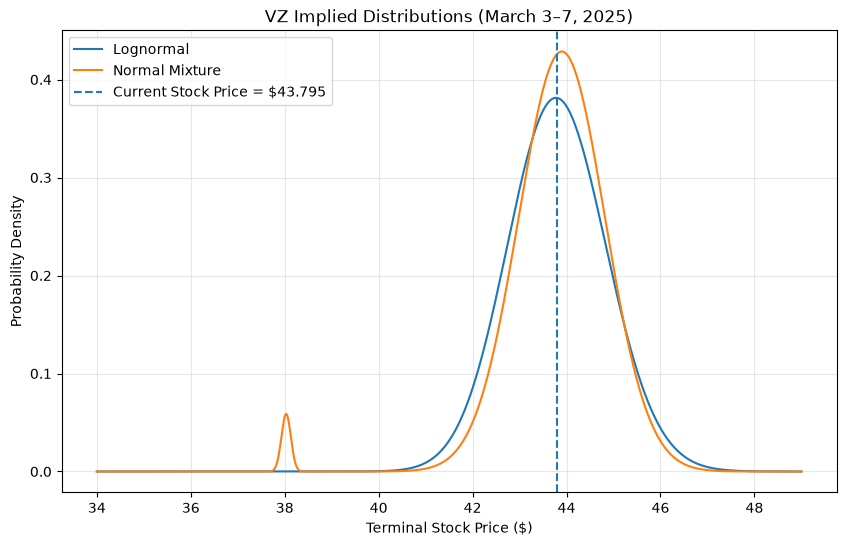

In [7]:
prices = np.linspace(34, 49, 1500)

# Lognormal density from Part 2
log_density = lognorm.pdf(
    prices, s=sigma_hat, scale=np.exp(mu_hat)
)

# Fitted two-normal mixture density
mix_density = (
    w * norm.pdf(prices, mu1, sd1)
    + (1 - w) * norm.pdf(prices, mu2, sd2)
)

plt.figure(figsize=(10, 6))

plt.plot(prices, log_density, label="Lognormal")
plt.plot(prices, mix_density, label="Normal Mixture")

plt.axvline(
    S0, linestyle="--",
    label=f"Current Stock Price = ${S0:.3f}"
)

plt.xlabel("Terminal Stock Price ($)")
plt.ylabel("Probability Density")
plt.title("VZ Implied Distributions (March 3–7, 2025)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [8]:
# Lognormal statistics
log_mean = np.exp(mu_hat + sigma_hat**2 / 2)
log_sd = log_mean * np.sqrt(np.expm1(sigma_hat**2))
log_skew = (np.exp(sigma_hat**2) + 2) * np.sqrt(
    np.expm1(sigma_hat**2)
)

# Mixture mean and variance
mix_mean = w * mu1 + (1 - w) * mu2

mix_variance = (
    w * (sd1**2 + (mu1 - mix_mean)**2)
    + (1 - w) * (sd2**2 + (mu2 - mix_mean)**2)
)

mix_sd = np.sqrt(mix_variance)

# Mixture skewness
mix_third = (
    w * ((mu1 - mix_mean)**3
         + 3 * (mu1 - mix_mean) * sd1**2)
    + (1 - w) * ((mu2 - mix_mean)**3
                 + 3 * (mu2 - mix_mean) * sd2**2)
)

mix_skew = mix_third / mix_sd**3

# Probability of a decline of at least 5%
threshold = 0.95 * S0

log_decline = norm.cdf(
    (np.log(threshold) - mu_hat) / sigma_hat
)

mix_decline = (
    w * norm.cdf((threshold - mu1) / sd1)
    + (1 - w) * norm.cdf((threshold - mu2) / sd2)
)

# Compare pricing accuracy
log_prices = call_price(K, mu_hat, sigma_hat)

log_rmse = np.sqrt(np.mean((log_prices - observed)**2))
mix_rmse = np.sqrt(np.mean((mixture_prices - observed)**2))

comparison = pd.DataFrame({
    "Measure": [
        "Mean terminal stock price",
        "Standard deviation",
        "Skewness",
        "Probability of 5% decline",
        "RMSE"
    ],
    "Lognormal": [
        f"${log_mean:.4f}",
        f"${log_sd:.4f}",
        f"{log_skew:.4f}",
        f"{log_decline:.2%}",
        f"${log_rmse:.4f}"
    ],
    "Normal Mixture": [
        f"${mix_mean:.4f}",
        f"${mix_sd:.4f}",
        f"{mix_skew:.4f}",
        f"{mix_decline:.2%}",
        f"${mix_rmse:.4f}"
    ]
})

print(comparison.to_string(index=False))


                  Measure Lognormal Normal Mixture
Mean terminal stock price  $43.8122       $43.8122
       Standard deviation   $1.0469        $1.1528
                 Skewness    0.0717        -1.7211
Probability of 5% decline     1.57%          2.08%
                     RMSE   $0.0317        $0.0197


Part 4. Independant Experiment - Sensitivity to Small changes in option prices

In [9]:
bid = clean_calls["bidPrc"].to_numpy()
ask = clean_calls["askPrc"].to_numpy()
threshold = 0.95 * S0

p_base = [w, mu2 - mu1, sd1, sd2]

def lognormal_stats(mu, sigma):
    skew = (np.exp(sigma**2) + 2) * np.sqrt(np.expm1(sigma**2))
    decline = norm.cdf((np.log(threshold) - mu) / sigma)
    return skew, decline

def mixture_stats(p):
    w_, m1, s1, m2, s2 = mixture_params(p)
    m = w_ * m1 + (1 - w_) * m2
    var = w_ * (s1**2 + (m1 - m)**2) + (1 - w_) * (s2**2 + (m2 - m)**2)
    third = (w_ * ((m1 - m)**3 + 3 * (m1 - m) * s1**2)
             + (1 - w_) * ((m2 - m)**3 + 3 * (m2 - m) * s2**2))
    decline = w_ * norm.cdf(threshold, m1, s1) + (1 - w_) * norm.cdf(threshold, m2, s2)
    return third / var**1.5, decline

rng = np.random.default_rng(42)
results = []

for i in range(200):
    prices = rng.uniform(bid, ask)

    # Lognormal: same objective as Part 2
    sigma_i = minimize_scalar(
        lambda s: np.sum((call_price(K, np.log(expected_ST) - s**2 / 2, s) - prices)**2),
        bounds=(0.000001, 0.30), method="bounded"
    ).x
    mu_i = np.log(expected_ST) - sigma_i**2 / 2

    # Mixture: same fit as Part 3
    fits = [
        least_squares(lambda p: mixture_call_price(K, p) - prices, x0=start,
                      bounds=([0.005, 0, 0.1, 0.1], [0.995, 15, 10, 10]),
                      max_nfev=1200)
        for start in starts + [p_base]
    ]
    p_i = min(fits, key=lambda f: np.sum(f.fun**2)).x

    results.append([*lognormal_stats(mu_i, sigma_i), *mixture_stats(p_i)])

sens = pd.DataFrame(results, columns=["ln_skew", "ln_decline", "mix_skew", "mix_decline"])
print("Done")

Done


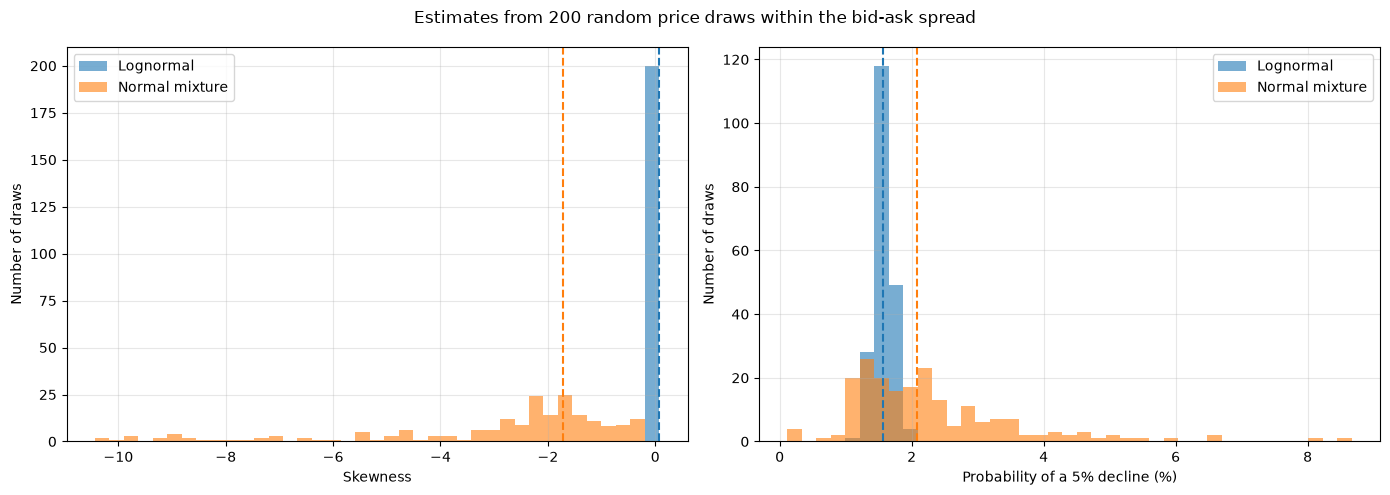

In [10]:
# Distribution of the estimates across draws
base_ln = lognormal_stats(mu_hat, sigma_hat)
base_mix = mixture_stats(p_base)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

panels = [
    ("skew", "Skewness", 1, 0),
    ("decline", "Probability of a 5% decline (%)", 100, 1),
]

for ax, (name, label, scale, k) in zip(axes, panels):
    ln = sens[f"ln_{name}"] * scale
    mix = sens[f"mix_{name}"] * scale
    bins = np.linspace(min(ln.min(), mix.min()), max(ln.max(), mix.max()), 40)
    ax.hist(ln, bins=bins, alpha=0.6, color="C0", label="Lognormal")
    ax.hist(mix, bins=bins, alpha=0.6, color="C1", label="Normal mixture")
    ax.axvline(base_ln[k] * scale, color="C0", linestyle="--")
    ax.axvline(base_mix[k] * scale, color="C1", linestyle="--")
    ax.set_xlabel(label)
    ax.set_ylabel("Number of draws")
    ax.grid(True, alpha=0.3)
    ax.legend()

fig.suptitle("Estimates from 200 random price draws within the bid-ask spread")
plt.tight_layout()
plt.show()

In [11]:
# Summary
rows = {
    "Lognormal: skewness": (base_ln[0], sens["ln_skew"], 1),
    "Lognormal: P(5% decline), %": (base_ln[1], sens["ln_decline"], 100),
    "Mixture: skewness": (base_mix[0], sens["mix_skew"], 1),
    "Mixture: P(5% decline), %": (base_mix[1], sens["mix_decline"], 100),
}

summary = pd.DataFrame(
    {
        name: [b * s, v.quantile(0.05) * s, v.median() * s, v.quantile(0.95) * s]
        for name, (b, v, s) in rows.items()
    },
    index=["Mid-price fit", "5th pct.", "Median", "95th pct."],
).T

print(summary.round(4).to_string())

                             Mid-price fit  5th pct.  Median  95th pct.
Lognormal: skewness                 0.0717    0.0697  0.0716     0.0737
Lognormal: P(5% decline), %         1.5720    1.3376  1.5577     1.8162
Mixture: skewness                  -1.7211   -8.9090 -2.1299    -0.4473
Mixture: P(5% decline), %           2.0844    1.0452  2.0135     4.7088
